Choose Input Mode:
1. Default Values
2. Custom Values


Enter your choice (1 or 2):  1



VISUALIZATION: DP TABLE HEATMAP
       M  Z  J  A  W  X  U
    ------------------------
   | [0  0  0  0  0  0  0  0]
 X | [0  0  0  0  0  0  1  1]
 M | [0  1  1  1  1  1  1  1]
 J | [0  1  1  2  2  2  2  2]
 Y | [0  1  1  2  2  2  2  2]
 A | [0  1  1  2  3  3  3  3]
 U | [0  1  1  2  3  3  3  4]
 Z | [0  1  2  2  3  3  3  4]

[V2] Matrix Topology Alignment Plot
   M Z J A W X U
X  .  .  .  .  .  █  . 
M  █  .  .  .  .  .  . 
J  .  .  █  .  .  .  . 
Y  .  .  .  .  .  .  . 
A  .  .  .  █  .  .  . 
U  .  .  .  .  .  .  █ 
Z  .  █  .  .  .  .  . 

Sequence Length: 4
Longest Common Subsequence: MJAU

 COMPREHENSIVE COMPLEXITY STATISTICS
Metric                    | Value
-------------------------------------------------------
Measured Execution Time   | 0.00006470 seconds
Calculated Space Usage    | 1080 bytes
Total Subproblems Solved  | 49

Sequence Length: 4
Longest Common Subsequence: MJAU

COMPREHENSIVE COMPLEXITY STATISTICS
Measured Execution Time  : 0.00006470 seconds
Calculated Spac

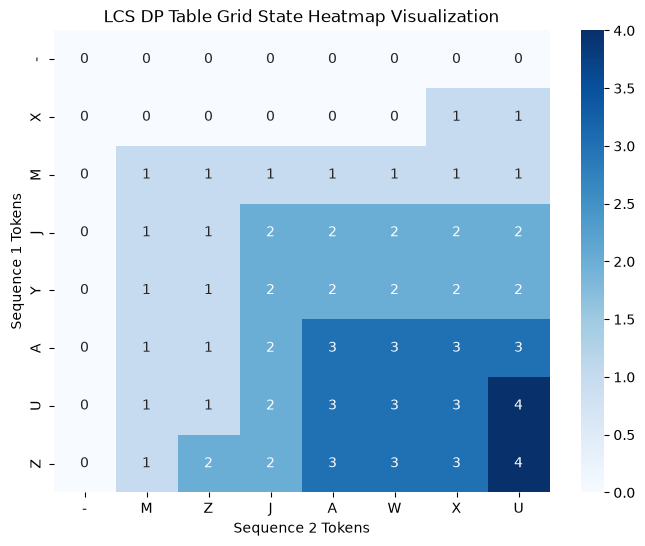

In [4]:
import sys
import time
import matplotlib.pyplot as plt
import seaborn as sns


def analyze_sequences(seq1, seq2):
    m, n = len(seq1), len(seq2)
    subproblems = 0

    start_time = time.perf_counter()
    dp = [[0] * (n + 1) for _ in range(m + 1)]

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            subproblems += 1
            if seq1[i - 1] == seq2[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])

    end_time = time.perf_counter()
    exec_time = end_time - start_time
    space_used = sys.getsizeof(dp) + sum(sys.getsizeof(row) for row in dp)

    lcs = []
    i, j = m, n
    while i > 0 and j > 0:
        if seq1[i - 1] == seq2[j - 1]:
            lcs.append(seq1[i - 1])
            i -= 1
            j -= 1
        elif dp[i - 1][j] >= dp[i][j - 1]:
            i -= 1
        else:
            j -= 1
    lcs.reverse()
    lcs_str = "".join(lcs)

    print("\n==========================================")
    print("VISUALIZATION: DP TABLE HEATMAP")
    print("==========================================")
    header = "       " + "  ".join(seq2)
    print(header)
    print("    " + "-" * (len(header) - 2))
    for r in range(m + 1):
        row_label = seq1[r - 1] if r > 0 else " "
        row_vals = "  ".join(f"{dp[r][c]}" for c in range(n + 1))
        print(f" {row_label} | [{row_vals}]")
    print("==========================================")

    print("\n[V2] Matrix Topology Alignment Plot")
    print("   " + " ".join(seq2))
    for i, char1 in enumerate(seq1):
        row_str = ""
        for j, char2 in enumerate(seq2):
            row_str += " █ " if char1 == char2 else " . "
        print(f"{char1} {row_str}")

    print(f"\nSequence Length: {dp[m][n]}")
    print(f"Longest Common Subsequence: {lcs_str}")

    print("\n" + "=" * 55)
    print(" COMPREHENSIVE COMPLEXITY STATISTICS")
    print("=" * 55)
    print(f"{'Metric':<25} | {'Value'}")
    print("-" * 55)
    print(f"{'Measured Execution Time':<25} | {exec_time:.8f} seconds")
    print(f"{'Calculated Space Usage':<25} | {space_used} bytes")
    print(f"{'Total Subproblems Solved':<25} | {subproblems}")
    print("=" * 55)

    print(f"\nSequence Length: {dp[m][n]}")
    print(f"Longest Common Subsequence: {lcs_str}")

    print("\n" + "=" * 55)
    print("COMPREHENSIVE COMPLEXITY STATISTICS")
    print("=" * 55)
    print(f"Measured Execution Time  : {exec_time:.8f} seconds")
    print(f"Calculated Space Usage   : {space_used} bytes")
    print(f"Total Subproblems Solved : {subproblems}")
    print("=" * 55)

    print("\nVisualizations...")
    plt.figure(figsize=(8, 6))
    xticklabels = ["-"] + list(seq2)
    yticklabels = ["-"] + list(seq1)
    sns.heatmap(
        dp,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=xticklabels,
        yticklabels=yticklabels,
    )
    plt.title("LCS DP Table Grid State Heatmap Visualization")
    plt.xlabel("Sequence 2 Tokens")
    plt.ylabel("Sequence 1 Tokens")
    plt.show()


print("Choose Input Mode:")
print("1. Default Values")
print("2. Custom Values")
choice = input("Enter your choice (1 or 2): ").strip()

if choice == "1":
    analyze_sequences("XMJYAUZ", "MZJAWXU")
elif choice == "2":
    seq1 = input("Enter the first sequence: ").strip()
    seq2 = input("Enter the second sequence: ").strip()
    if seq1 and seq2:
        analyze_sequences(seq1, seq2)
    else:
        print("Error: Both sequences must contain at least one character.")
else:
    print("Invalid choice selected.")